In [1]:
import sys; sys.path.append("..")  
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.config import INTERIM_DIR

df = pd.read_csv(INTERIM_DIR / "era5_patna_2011_2025.csv", parse_dates=["time"])
df["time"] = df["time"].dt.tz_localize("UTC")
df = df.set_index("time")
df = df[df.index.year <= 2024]          # test year (2025) stays unseen

ist = df.index.tz_convert("Asia/Kolkata")   # local time, for cycles only
df["hour"] = ist.hour
df["month"] = ist.month
df.shape, df.index.min(), df.index.max()

((122736, 11),
 Timestamp('2011-01-01 00:00:00+0000', tz='UTC'),
 Timestamp('2024-12-31 23:00:00+0000', tz='UTC'))

In [2]:
yearly = df.groupby(df.index.year).agg(
    temp_mean=("temperature_2m", "mean"),
    temp_min=("temperature_2m", "min"),
    temp_max=("temperature_2m", "max"),
    pressure_mean=("surface_pressure", "mean"),
    rain_total_mm=("precipitation", "sum"),
)
yearly.round(1)

,temp_mean,temp_min,temp_max,pressure_mean,rain_total_mm
time,,,,,
2011,25.6,5.9,42.7,1000.6,1122.6
2012,25.9,7.1,45.4,1000.2,1063.6
2013,25.5,3.3,42.3,1001.1,1145.5
2014,25.6,6.8,43.6,1001.8,911.6
2015,26.2,7.4,44.6,1002.2,878.5
2016,26.4,6.8,43.4,1001.3,1195.3
2017,26.2,6.7,43.5,1001.4,1031.4
2018,25.8,6.6,43.1,1001.2,943.5
2019,26.1,5.3,44.9,1002.0,1221.2


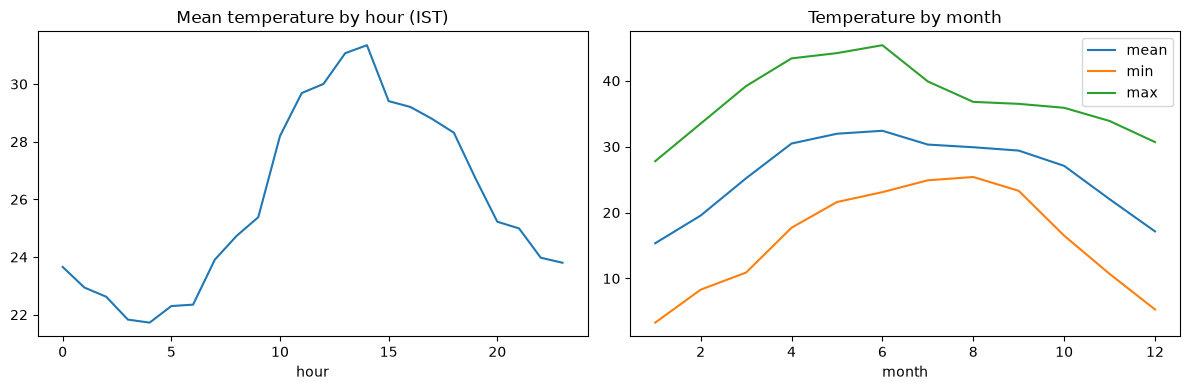

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df.groupby("hour")["temperature_2m"].mean().plot(ax=ax[0], title="Mean temperature by hour (IST)")
df.groupby("month")["temperature_2m"].agg(["mean", "min", "max"]).plot(ax=ax[1], title="Temperature by month")
plt.tight_layout(); plt.show()

exact zeros: 84.6% | 0 < x < 0.1 mm: 0.0%
count    18902.00
mean         0.83
std          1.22
min          0.10
50%          0.40
90%          2.00
99%          6.00
max         18.50
Name: precipitation, dtype: float64


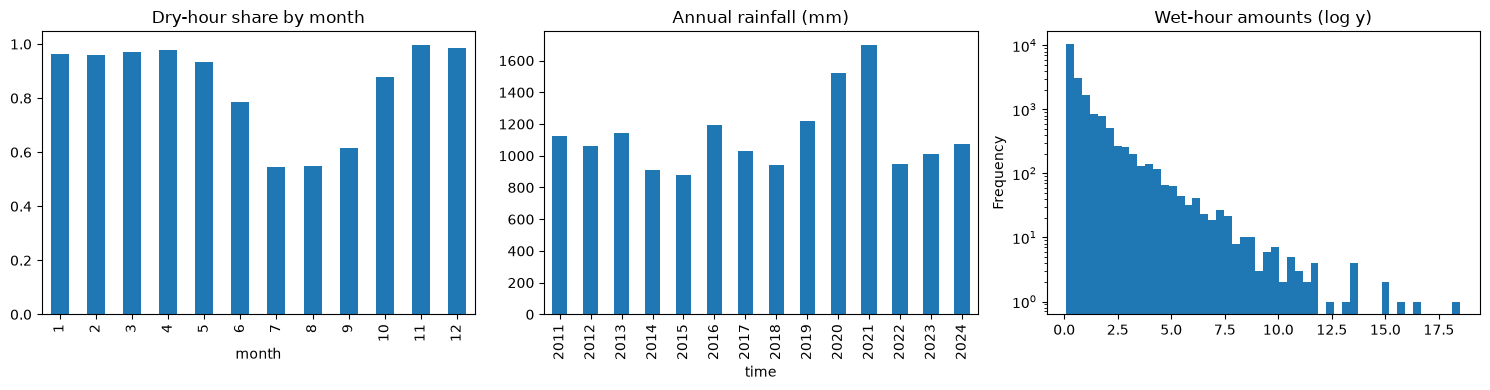

In [4]:
rain = df["precipitation"]
print("exact zeros:", f"{(rain == 0).mean():.1%}", "| 0 < x < 0.1 mm:", f"{((rain > 0) & (rain < 0.1)).mean():.1%}")
print(rain[rain >= 0.1].describe(percentiles=[.5, .9, .99]).round(2))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
(rain == 0).groupby(df["month"]).mean().plot.bar(ax=ax[0], title="Dry-hour share by month")
rain.groupby(df.index.year).sum().plot.bar(ax=ax[1], title="Annual rainfall (mm)")
rain[rain >= 0.1].plot.hist(bins=50, log=True, ax=ax[2], title="Wet-hour amounts (log y)")
plt.tight_layout(); plt.show()

In [5]:
lags = [1, 3, 6, 12, 24, 48, 72]
for col in ["temperature_2m", "surface_pressure", "relative_humidity_2m", "precipitation"]:
    print(f"{col:22s}", [round(df[col].autocorr(l), 2) for l in lags])

temperature_2m         [np.float64(0.98), np.float64(0.91), np.float64(0.75), np.float64(0.56), np.float64(0.97), np.float64(0.96), np.float64(0.94)]
surface_pressure       [np.float64(1.0), np.float64(0.97), np.float64(0.94), np.float64(0.96), np.float64(0.97), np.float64(0.94), np.float64(0.93)]
relative_humidity_2m   [np.float64(0.96), np.float64(0.82), np.float64(0.52), np.float64(0.19), np.float64(0.92), np.float64(0.87), np.float64(0.83)]
precipitation          [np.float64(0.69), np.float64(0.39), np.float64(0.27), np.float64(0.21), np.float64(0.18), np.float64(0.13), np.float64(0.1)]


In [6]:
daily = df["precipitation"].tz_convert("Asia/Kolkata").resample("D").sum()
daily_train = daily[:"2022-12-31"]     # decide thresholds from training years only

print(daily_train.describe(percentiles=[.9, .95, .99]).round(1))
for t in [64.5, 115.6]:                # IMD heavy / very heavy cutoffs: verify these yourself
    print(f"days >= {t} mm:", int((daily_train >= t).sum()))

count    4383.0
mean        3.1
std         7.9
min         0.0
90%        10.3
95%        17.8
99%        34.8
max       112.0
Name: precipitation, dtype: float64
days >= 64.5 mm: 12
days >= 115.6 mm: 0


In [7]:
tr = df[df.index.year <= 2022]
clim = tr.groupby(["month", "hour"])["temperature_2m"].transform("mean")
anom = tr["temperature_2m"] - clim
print([round(anom.autocorr(l), 2) for l in [1, 3, 6, 12, 24, 48, 72]])

[np.float64(0.97), np.float64(0.89), np.float64(0.78), np.float64(0.65), np.float64(0.74), np.float64(0.55), np.float64(0.41)]


In [8]:
for lag in [-2, -1, 0, 1, 2]:
    print(lag, round(df["precipitation"].corr(df["relative_humidity_2m"].shift(lag)), 3))

-2 0.195
-1 0.192
0 0.181
1 0.165
2 0.156
